# Chapter 8: Numbers Across Groups

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 8.1 Picking Out One Group

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('book.mplstyle')

customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancels = pd.read_csv('cancellations.csv',
                      parse_dates=['cancel_date'])
tickets = pd.read_csv('support_tickets.csv',
                      parse_dates=['opened_date'])

In [2]:
orders_region = orders.merge(customers[['customer_id', 'region']],
                             on='customer_id', validate='many_to_one')
regions = ['Northeast', 'Midwest', 'South', 'West']
orders_region[['order_id', 'region', 'delivery_days']].head()

,order_id,region,delivery_days
0,100001,South,2
1,100002,South,2
2,100003,West,4
3,100004,West,5
4,100005,Midwest,4


### Filtering with a mask

In [3]:
is_west = orders_region['region'] == 'West'
west_orders = orders_region[is_west]
print(f'West orders: {len(west_orders)}')
print(f"West average: {west_orders['delivery_days'].mean():.2f} days")

West orders: 8281
West average: 3.88 days


### `df.loc[]`

In [4]:
west_days = orders_region.loc[is_west, 'delivery_days']
print(f'{west_days.mean():.2f}')

3.88


In [5]:
orders_region.loc[is_west, ['order_id', 'delivery_days']].head(3)

,order_id,delivery_days
2,100003,4
3,100004,5
5,100006,3


In [6]:
late_west = (orders_region['region'] == 'West') & (
    orders_region['delivery_days'] > 5)
not_west = ~is_west
print(f'Late West boxes: {late_west.sum()}')
print(f'Orders outside the West: {not_west.sum()}')

Late West boxes: 1342
Orders outside the West: 20491


## 8.2 Split, Apply, Combine

In [7]:
tiny = pd.DataFrame({
    'region': ['West', 'South', 'West', 'South', 'West', 'South'],
    'days': [4, 3, 5, 3, 3, 2]})
tiny

,region,days
0,West,4
1,South,3
2,West,5
3,South,3
4,West,3
5,South,2


In [8]:
for name, group in tiny.groupby('region'):
    print(name)
    print(group)

South
  region  days
1  South     3
3  South     3
5  South     2
West
  region  days
0   West     4
2   West     5
4   West     3


In [9]:
tiny.groupby('region')['days'].mean()

region
South    2.666667
West     4.000000
Name: days, dtype: float64

### `df.groupby()`

In [10]:
avg_days = orders_region.groupby('region')['delivery_days'].mean()
avg_days.round(2)

region
Midwest      3.07
Northeast    2.79
South        3.31
West         3.88
Name: delivery_days, dtype: float64

In [11]:
avg_days.sort_values(ascending=False).round(2)

region
West         3.88
South        3.31
Midwest      3.07
Northeast    2.79
Name: delivery_days, dtype: float64

### Counting rows in each group

In [12]:
by_plan = customers.groupby('plan')
pd.DataFrame({'rows': by_plan.size(),
              'ages_filled_in': by_plan['age'].count()})

,rows,ages_filled_in
plan,,
Basic,1887,1813
Premium,812,779
Standard,1511,1451


### Getting a DataFrame back

In [13]:
orders_region.groupby('region', as_index=False)['delivery_days'].mean()

,region,delivery_days
0,Midwest,3.072793
1,Northeast,2.787595
2,South,3.313633
3,West,3.880811


## 8.3 Several Numbers at Once with `.agg()`

### `.agg()`

In [14]:
days_by_region = orders_region.groupby('region')['delivery_days']
days_by_region.agg(['mean', 'median', 'std', 'count']).round(2)

,mean,median,std,count
region,,,,
Midwest,3.07,3.0,1.45,5289
Northeast,2.79,3.0,1.37,7368
South,3.31,3.0,1.52,7834
West,3.88,4.0,1.69,8281


### Named aggregations

In [15]:
orders_region['late'] = orders_region['delivery_days'] > 5
region_summary = orders_region.groupby('region').agg(
    orders=('order_id', 'count'),
    avg_days=('delivery_days', 'mean'),
    late_rate=('late', 'mean'))
region_summary.round(3)

,orders,avg_days,late_rate
region,,,
Midwest,5289,3.073,0.062
Northeast,7368,2.788,0.039
South,7834,3.314,0.083
West,8281,3.881,0.162


### Add-on amounts by region

In [16]:
add_ons = orders_region[orders_region['order_type'] == 'Add-on']
gifts = add_ons['items'] >= 10
regular = add_ons[~gifts]
regular.groupby('region')['amount'].agg(
    ['count', 'mean', 'median']).round(2).loc[regions]

,count,mean,median
region,,,
Northeast,1142,22.38,18.46
Midwest,849,21.82,17.96
South,1175,22.65,18.15
West,1330,26.78,21.79


### Total spend by plan

In [17]:
spend = orders.groupby('customer_id')['amount'].sum()
spend = spend.rename('total_spend').reset_index()
customers = customers.merge(spend, on='customer_id',
                            validate='one_to_one')
customers[['customer_id', 'plan', 'total_spend']].head()

,customer_id,plan,total_spend
0,1001,Basic,435.37
1,1002,Basic,8.00
2,1003,Standard,479.02
3,1004,Basic,8.00
4,1005,Basic,56.00


In [18]:
plan_order = ['Basic', 'Standard', 'Premium']
spend_by_plan = customers.groupby('plan').agg(
    customers=('total_spend', 'count'),
    mean_spend=('total_spend', 'mean'),
    median_spend=('total_spend', 'median'),
    total=('total_spend', 'sum'))
spend_by_plan.round(0).loc[plan_order]

,customers,mean_spend,median_spend,total
plan,,,,
Basic,1887,78.0,49.0,146653.0
Standard,1511,200.0,139.0,302720.0
Premium,812,401.0,297.0,325684.0


In [19]:
shares = pd.DataFrame({
    'customer_share': (spend_by_plan['customers']
                       / spend_by_plan['customers'].sum()),
    'revenue_share': (spend_by_plan['total']
                      / spend_by_plan['total'].sum())})
shares.round(3).loc[plan_order]

,customer_share,revenue_share
plan,,
Basic,0.448,0.189
Standard,0.359,0.391
Premium,0.193,0.420


### Cancellation rate by channel, and spend by city

In [20]:
customers['cancelled'] = customers['customer_id'].isin(
    cancels['customer_id'])
by_channel = customers.groupby('channel').agg(
    customers=('cancelled', 'count'),
    cancel_rate=('cancelled', 'mean'))
by_channel.sort_values('cancel_rate').round(3)

,customers,cancel_rate
channel,,
Referral,548,0.409
Email,445,0.508
Search,1472,0.539
Podcast,678,0.624
Social,1067,0.658


In [21]:
by_city = customers.groupby('city').agg(
    customers=('cancelled', 'count'),
    avg_spend=('total_spend', 'mean'),
    cancel_rate=('cancelled', 'mean'))
by_city = by_city.sort_values('avg_spend', ascending=False)
print(by_city.head(3).round(2))
print(by_city.tail(3).round(2))

             customers  avg_spend  cancel_rate
city                                          
Minneapolis        141     231.51         0.52
Pittsburgh          95     208.05         0.61
Detroit            139     205.58         0.50
         customers  avg_spend  cancel_rate
city                                      
Houston        295     160.90         0.55
Boston         193     148.06         0.51
Denver         176     133.80         0.68


### Hours to resolve by ticket topic

In [22]:
tickets.groupby('topic')['hours_to_resolve'].agg(
    ['count', 'mean', 'median']).round(1)

,count,mean,median
topic,,,
Billing,250,8.9,6.0
Change address,153,9.0,5.7
Late delivery,612,9.8,6.1
Other,151,9.4,5.3
Product quality,214,9.0,6.5


## 8.4 Grouping by Two Columns

In [23]:
by_plan_channel = customers.groupby(['plan', 'channel']).agg(
    customers=('cancelled', 'count'),
    cancel_rate=('cancelled', 'mean'))
by_plan_channel.round(3)

customers  cancel_rate
plan     channel                         
Basic    Email           144        0.722
         Podcast         591        0.665
         Referral        143        0.469
         Search          477        0.711
         Social          532        0.782
Premium  Email           107        0.346
         Podcast          14        0.286
         Referral        138        0.348
         Search          392        0.362
         Social          161        0.447
Standard Email           194        0.438
         Podcast          73        0.356
         Referral        267        0.408
         Search          603        0.519
         Social          374        0.572

## 8.5 Pivot Tables

### `pd.pivot_table()`

In [24]:
cancel_grid = customers.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='mean')
cancel_grid.round(3).loc[plan_order]

channel,Email,Podcast,Referral,Search,Social
plan,,,,,
Basic,0.722,0.665,0.469,0.711,0.782
Standard,0.438,0.356,0.408,0.519,0.572
Premium,0.346,0.286,0.348,0.362,0.447


### Totals with `margins=True`

In [25]:
cancel_grid = customers.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='mean', margins=True)
cancel_grid.round(3).loc[plan_order + ['All']]

channel,Email,Podcast,Referral,Search,Social,All
plan,,,,,,
Basic,0.722,0.665,0.469,0.711,0.782,0.699
Standard,0.438,0.356,0.408,0.519,0.572,0.494
Premium,0.346,0.286,0.348,0.362,0.447,0.373
All,0.508,0.624,0.409,0.539,0.658,0.563


### Counting what each cell rests on

In [26]:
customers.pivot_table(
    values='cancelled', index='plan', columns='channel',
    aggfunc='count', margins=True).loc[plan_order + ['All']]

channel,Email,Podcast,Referral,Search,Social,All
plan,,,,,,
Basic,144,591,143,477,532,1887
Standard,194,73,267,603,374,1511
Premium,107,14,138,392,161,812
All,445,678,548,1472,1067,4210


### Other `aggfunc` values and `fill_value`

In [27]:
orders_region.pivot_table(
    values='delivery_days', index='region',
    columns='order_type', aggfunc='median').loc[regions]

order_type,Add-on,Subscription
region,,
Northeast,3.0,3.0
Midwest,3.0,3.0
South,3.0,3.0
West,4.0,4.0


## 8.6 Adding the Group's Number to Every Row

### `groupby().transform()`

In [28]:
grouped_days = orders_region.groupby('region')['delivery_days']
n_mean = len(grouped_days.mean())
n_transform = len(grouped_days.transform('mean'))
print(f'mean():            {n_mean} values')
print(f"transform('mean'): {n_transform} values")

mean():            4 values
transform('mean'): 28772 values


In [29]:
orders_region['region_avg_days'] = grouped_days.transform('mean')
orders_region['days_vs_region'] = (orders_region['delivery_days']
                                   - orders_region['region_avg_days'])
orders_region[['order_id', 'region', 'delivery_days',
               'region_avg_days', 'days_vs_region']].head(4).round(2)

,order_id,region,delivery_days,region_avg_days,days_vs_region
0,100001,South,2,3.31,-1.31
1,100002,South,2,3.31,-1.31
2,100003,West,4,3.88,0.12
3,100004,West,5,3.88,1.12


In [30]:
by_region_gap = orders_region.groupby('region')['days_vs_region']
print(np.allclose(by_region_gap.mean(), 0))

True


### A customer's share of their region

In [31]:
region_total = customers.groupby('region')['total_spend'].transform(
    'sum')
customers['share_of_region'] = customers['total_spend'] / region_total
top_shares = customers.sort_values('share_of_region', ascending=False)
top_shares[['customer_id', 'region', 'plan', 'total_spend',
            'share_of_region']].head(4).round(4)

,customer_id,region,plan,total_spend,share_of_region
1009,2010,Midwest,Premium,1527.18,0.0106
35,1036,Midwest,Premium,1274.66,0.0088
1239,2240,Midwest,Premium,1259.97,0.0087
325,1326,Midwest,Premium,1239.88,0.0086


In [32]:
customers.groupby('region')['share_of_region'].sum()

region
Midwest      1.0
Northeast    1.0
South        1.0
West         1.0
Name: share_of_region, dtype: float64

## 8.7 Box Plots by Group

### `sns.boxplot()` with `x=` and `y=`

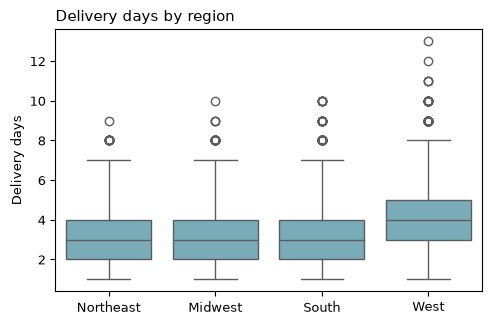

In [33]:
ax = sns.boxplot(data=orders_region, x='region', y='delivery_days',
                 order=regions, color='#6fb3c2')
ax.set_title('Delivery days by region')
ax.set_xlabel('')
ax.set_ylabel('Delivery days')
plt.show()

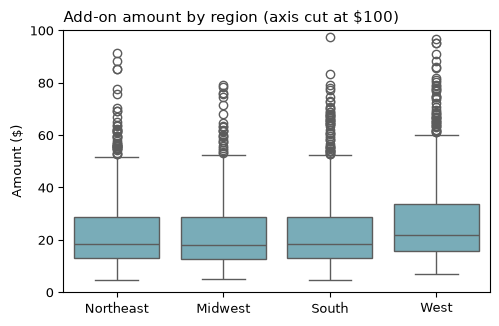

In [34]:
ax = sns.boxplot(data=add_ons, x='region', y='amount',
                 order=regions, color='#6fb3c2')
ax.set_ylim(0, 100)
ax.set_title('Add-on amount by region (axis cut at $100)')
ax.set_xlabel('')
ax.set_ylabel('Amount ($)')
plt.show()

### Total spend by plan

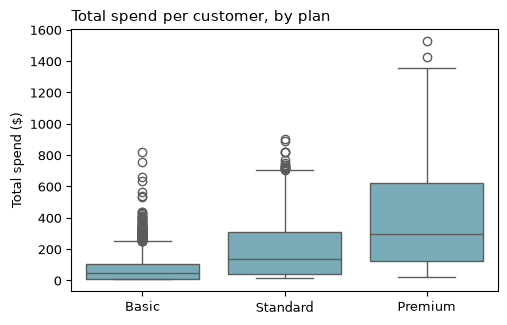

In [35]:
ax = sns.boxplot(data=customers, x='plan', y='total_spend',
                 order=plan_order, color='#6fb3c2')
ax.set_title('Total spend per customer, by plan')
ax.set_xlabel('')
ax.set_ylabel('Total spend ($)')
plt.show()

In [36]:
spend_groups = customers.groupby('plan')['total_spend']
pd.DataFrame({'lower edge': spend_groups.quantile(0.25),
              'upper edge': spend_groups.quantile(0.75)}
             ).round(0).loc[plan_order]

,lower edge,upper edge
plan,,
Basic,8.0,105.0
Standard,42.0,306.0
Premium,122.0,619.0


## 8.8 Violin Plots

### `sns.violinplot()`

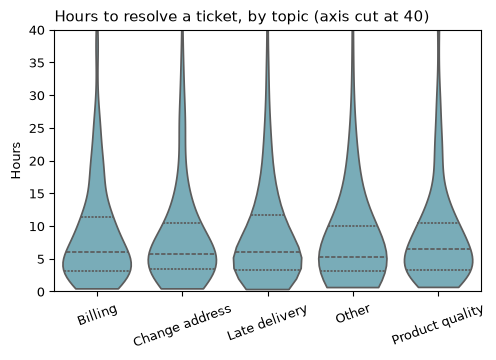

In [37]:
topics = ['Billing', 'Change address', 'Late delivery',
          'Other', 'Product quality']
ax = sns.violinplot(data=tickets, x='topic', y='hours_to_resolve',
                    order=topics, color='#6fb3c2', cut=0,
                    inner='quart', density_norm='width')
ax.set_ylim(0, 40)
ax.set_title('Hours to resolve a ticket, by topic (axis cut at 40)')
ax.set_xlabel('')
ax.set_ylabel('Hours')
plt.xticks(rotation=20)
plt.show()